# 113221023 數學系碩二 陳宗毅

# **Pneumonia Detection by CNN with Data Augmentation**

2020/03/15
+ 本範例利用 TensorFlow 2.0 架構下的 `tf.keras` 套件，來建立 CNN 模型，透過胸腔 X-光片影像進行肺炎偵測。
+ 資料部份：
    - 將 "Chest_Xray" 影像資料匯入，並修改、統一其影像尺寸為 (224, 224, 3)。
    - 其中，資料匯入區分為 train、test 和 val 三個部分。

---------------------------
## CONTENT
1. [ APPROACH ](#approach)
2. [ Data Preprocessing ](#preprocessing)
    + [ Importing Training Datasets ](#TrainData)
    + [ Importing Validation Datasets ](#ValData)
    + [ Importing Test Datasets ](#TestData)
3. [ (A)MobileNetv2 Model with *tf.keras* ](#MobileNetv2)
    + [ Forward Propagation ](#Forwardpropagation)
    + [ Model Summary & Plotting the Model ](#ModelSummary)
- [ Start Training - from Coarse to Fine ](#StartTraining)
    + [ Setting Hyperparameters ](#SettingHyperparameters)
    + [ STAGE 1 - Coarse Training without Data Augmentation ](#Stage1)
        + [ Backpropagation for STAGE 1 ](#Backpropagation1)
    + [ STAGE 2 - Fine Training *with* Data Augmentation ](#Stage2)
        + [ Backpropagation for STAGE 2 ](#Backpropagation2)
    + [ STAGE 3 - Fine Training *with* Unfreezing layer ](#Stage3)
        + [ Backpropagation for STAGE 3 ](#Backpropagation3)
- [ Saving the Entire Model with HDF5 Format ](#SavingEntireModel)
4. [ (B)ResNet50 Model with *tf.keras* ](#ResNet50)
    + [ Forward Propagation ](#Forwardpropagation)
    + [ Model Summary & Plotting the Model ](#ModelSummary)
- [ Start Training - from Coarse to Fine ](#StartTraining)
    + [ Setting Hyperparameters ](#SettingHyperparameters)
    + [ STAGE 1 - Coarse Training without Data Augmentation ](#Stage1)
        + [ Backpropagation for STAGE 1 ](#Backpropagation1)
    + [ STAGE 2 - Fine Training *with* Data Augmentation ](#Stage2)
        + [ Backpropagation for STAGE 2 ](#Backpropagation2)
    + [ STAGE 3 - Fine Training *with* Unfreezing layer ](#Stage3)
        + [ Backpropagation for STAGE 3 ](#Backpropagation3)
- [ Saving the Entire Model with HDF5 Format ](#SavingEntireModel)
5. [ Conclusion ](#Conclusion)
---------------------------

In [ ]:
import tensorflow as tf
tf.__version__

'2.19.0'

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mimg
import seaborn as sns
%matplotlib inline
from sklearn.metrics import confusion_matrix

import cv2
import os
import glob

from os import listdir, makedirs, getcwd, remove
from os.path import isfile, join, abspath, exists, isdir, expanduser
from PIL import Image
from pathlib import Path
from skimage.io import imread
from skimage.transform import resize
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, precision_score, recall_score, fbeta_score
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, SeparableConv2D
from tensorflow.keras.layers import GlobalMaxPooling2D, Flatten, Dropout
from tensorflow.keras.layers import BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.optimizers.schedules import PolynomialDecay

import keras

<a id='preprocessing'></a>
## Data Preprocessing

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [ ]:
# Input data files are available in the "../input/" directory.
INPUT_PATH = "/kaggle/input/chest-xray-pneumonia/chest_xray"

# List the files in the input directory.
print(os.listdir(INPUT_PATH))

['chest_xray', '__MACOSX', 'val', 'test', 'train']


### Import X-ray Image Datasets from /train, /val & /test

In [ ]:
def load_data(files_dir='/train'):
    # list of the paths of all the image files
    normal = Path(files_dir + '/NORMAL').glob('*.jpeg')
    pneumonia = Path(files_dir + '/PNEUMONIA').glob('*.jpeg')

    # NORMAL = 0
    normal_data = [(image, 0) for image in normal]

    # PNEUMONIA => bacteria = 1, virus = 2
    pneumonia_data = [
        (image, 1 if "bacteria" in image.name.lower() else 2)
        for image in pneumonia
    ]

    # 合併
    image_data = normal_data + pneumonia_data

    # Get a pandas dataframe for the data paths
    image_data = pd.DataFrame(image_data, columns=['image', 'label'])

    # Shuffle the data
    image_data = image_data.sample(frac=1., random_state=100).reset_index(drop=True)

    # Import images & labels
    x_images, y_labels = ([data_input(image_data.iloc[i][:]) for i in range(len(image_data))],
                         [image_data.iloc[i][1] for i in range(len(image_data))])

    # Convert to numpy array
    x_images = np.array(x_images)
    y_labels = np.array(y_labels)

    print("Total number of images: ", x_images.shape)
    print("Total number of labels: ", y_labels.shape)

    return x_images, y_labels


In [ ]:
def data_input(dataset):
    for image_file in dataset:
        image = cv2.imread(str(image_file))
        image = cv2.resize(image, (224,224))

        # 1. 若為灰階 → 補成三通道
        if len(image.shape) == 2 or image.shape[2] == 1:
            image = np.dstack([image, image, image])

        # 2. BGR → LAB (CLAHE 最佳空間)
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)

        # 3. CLAHE (建議參數：clipLimit=2.0, tileGridSize=8x8)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l)

        # 4. 合併 CLAHE 後 L channel + a,b，轉回 RGB
        lab = cv2.merge((cl, a, b))
        image = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

        # 5. Normalization
        image = image.astype(np.float32) / 255.

        return image


<a id="TrainData"></a>
+ ### Importing Training Datasets

In [ ]:
# Import train dataset...
x_train, y_train = load_data(files_dir=INPUT_PATH + '/train')

print(x_train.shape)
print(y_train.shape)

/tmp/ipython-input-288827761.py:26: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  [image_data.iloc[i][1] for i in range(len(image_data))])


Total number of images:  (5216, 224, 224, 3)
Total number of labels:  (5216,)
(5216, 224, 224, 3)
(5216,)


<a id="ValData"></a>
+ ### Importing Validation Datasets

In [ ]:
# Import validation dataset...
x_val, y_val = load_data(files_dir=INPUT_PATH + '/val')

print(x_val.shape)
print(y_val.shape)

Total number of images:  (16, 224, 224, 3)
Total number of labels:  (16,)
(16, 224, 224, 3)
(16,)


/tmp/ipython-input-288827761.py:26: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  [image_data.iloc[i][1] for i in range(len(image_data))])


<a id="TestData"></a>
+ ### Importing Test Datasets

In [ ]:
# Import test dataset...
x_test, y_test = load_data(files_dir=INPUT_PATH + '/test')

print(x_test.shape)
print(y_test.shape)

Total number of images:  (624, 224, 224, 3)
Total number of labels:  (624,)
(624, 224, 224, 3)
(624,)


/tmp/ipython-input-288827761.py:26: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  [image_data.iloc[i][1] for i in range(len(image_data))])


In [ ]:
# Counts for both classes
count_result = pd.Series(y_test).value_counts()
print('Total of Test Data : ', len(y_test), '  (0 : Normal; 1 : Bacteria; 2 : Virus)')
print('------------------')
print(count_result)
print('------------------')
print('1 :  ', count_result[1]/sum(count_result))
print('0 :  ', count_result[0]/sum(count_result))
print('2 :  ', count_result[2]/sum(count_result))

Total of Test Data :  624   (0 : Normal; 1 : Bacteria; 2 : Virus)
------------------
1    242
0    234
2    148
Name: count, dtype: int64
------------------
1 :   0.38782051282051283
0 :   0.375
2 :   0.23717948717948717


<a id='MobileNetV2'></a>
# (A) **MobileNetV2** by *tf.keras*

<a id="Forwardpropagation"></a>
+ ### Forward Propagation - with Batch Normalization and Dropout


In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224,224) + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False


inputs = keras.Input(shape=(224,224) + (3,))

# MobileNet 要做這個前處理
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x)

# ---- 加 CNN Layer ----
x = SeparableConv2D(256, (3,3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = SeparableConv2D(128, (3,3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = MaxPooling2D((2,2))(x)
# ---- GAP + Dropout ----
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)

outputs = Dense(3, activation="softmax")(x)

model = keras.Model(inputs, outputs)


<a id="ModelSummary"></a>
+ ### Model Summary & Plotting the Model

In [ ]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_4 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_4 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_8              │ (None, 7, 7, 256)      │       339,456 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_9              │ (None, 7, 7, 128)      │        35,200 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,634,563 (10.05 MB)

 Trainable params: 375,811 (1.43 MB)

 Non-trainable params: 2,258,752 (8.62 MB)

<a id="StartTraining"></a>
## Start Training with Data Augmentation

<a id="SettingHyperparameters"></a>
+ ### Setting Hyperparameters for Training Process
>+ 由於 validation dataset 只有 16 筆影像資料 (太少了些)，因此，直接將 training datasets (5216 images) 分割出 4200 筆的 training 資料 (80.5% 資料量)，其餘的 1016 張 X-ray 影像資料做為 validation 資料集。
>+ **[ Learning-Rate Decay ] : basic learning rate = 0.001**
    + 在 STAGE 1 中，設定 basic learning rate 的 1/10 為 decay rate，取 epoch 數為 10 時，每個 epoch 的 GPU 運算時間約為 20 秒。
    + 在 STAGE 2 中，設定 learning_rate 為 basic learning rate 的 1/10 (decay rate =  learning_rate/100)，取 epoch 數為 20，每個 epoch 的 GPU 運算時間約為 45 秒。

In [ ]:
batch_size = 16
epochs_stage_1 = 20
epochs_stage_2 = 20
epochs_stage_3 = 40
train_data_num = 4200
unfreeze = 120
class_weight = {0: 1.2, 1: 1.0, 2: 1.0}

<a id="Stage1"></a>
+ ### STAGE 1 : Coarse Training *without* Data Augmentation

<a id="Backpropagation1"></a>
> + ### Backpropagation - *Optimizer*, *Loss Function* & *Accuracy* for < STAGE 1 >

In [ ]:
lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-2,
    decay_steps=(train_data_num * epochs_stage_1) // batch_size,
    end_learning_rate=1e-5,
    power=1.0,
)

# Adam Optimizer with Learning-rate Decay
opt = Adam(learning_rate=lr_schedule)

model.compile(optimizer=opt,
              loss = tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
## data_augmentation = False
print('Not using data augmentation.')
epochs = epochs_stage_1


history_no_data_aug = model.fit(x_train[:train_data_num], y_train[:train_data_num],
                               batch_size=batch_size,
                               epochs=epochs,
                               validation_data=(x_train[train_data_num:], y_train[train_data_num:]),
                               class_weight=class_weight,
                               shuffle=False)

Not using data augmentation.
Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 40s 98ms/step - accuracy: 0.5814 - loss: 1.0127 - val_accuracy: 0.4990 - val_loss: 4.2159
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.6970 - loss: 0.6667 - val_accuracy: 0.5699 - val_loss: 1.5182
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7277 - loss: 0.5982 - val_accuracy: 0.4803 - val_loss: 1.7662
Epoch 4/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7431 - loss: 0.5728 - val_accuracy: 0.7549 - val_loss: 0.5634
Epoch 5/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7485 - loss: 0.5444 - val_accuracy: 0.6270 - val_loss: 1.0297
Epoch 6/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7572 - loss: 0.5472 - val_accuracy: 0.6407 - val_loss: 0.9228
Epoch 7/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7738 - loss: 0.5154 - val_accuracy: 0.7972 - val_loss: 0.5066
Epoch 8/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.

> ### Validation-Curve Diagrams for STAGE 1 - Training without Data Augmentation

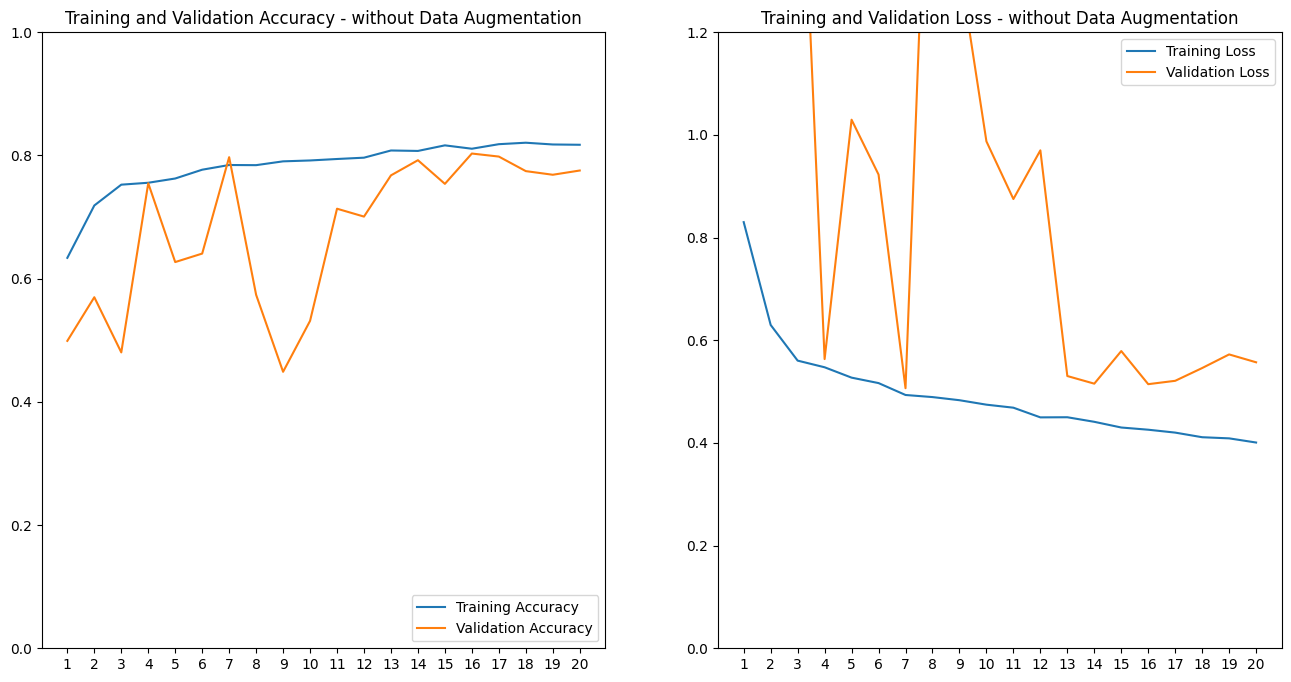

In [ ]:
acc = history_no_data_aug.history['accuracy']
val_acc = history_no_data_aug.history['val_accuracy']

loss = history_no_data_aug.history['loss']
val_loss = history_no_data_aug.history['val_loss']

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Accuracy - without Data Augmentation')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylim(0, 1.2)
plt.xticks(epochs_range)
plt.title('Training and Validation Loss - without Data Augmentation')
plt.show()

> ### Evaluation for Test Datasets in < STAGE 1 >

In [ ]:
# Score trained model.
loss, acc = model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.7122 - loss: 2.0022
Test loss: 1.8661514520645142
Test accuracy: 0.7147436141967773


In [ ]:
# 得到預測機率
y_pred_prob = model.predict(x_test)  # shape: (num_samples, 3)

# 取最大機率的索引 -> 預測類別
y_pred = np.argmax(y_pred_prob, axis=1)  # shape: (num_samples,)

# 確認 y_test 和 y_pred
print("前 10 筆預測:", y_pred[:10])
print("前 10 筆真實:", y_test[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 396ms/step
前 10 筆預測: [2 0 1 2 2 1 2 1 2 2]
前 10 筆真實: [2 0 1 0 2 1 2 1 2 0]


> ### Confusion Matrix for < STAGE 1 >

[[108  38  88]
 [  4 230   8]
 [  3  37 108]]


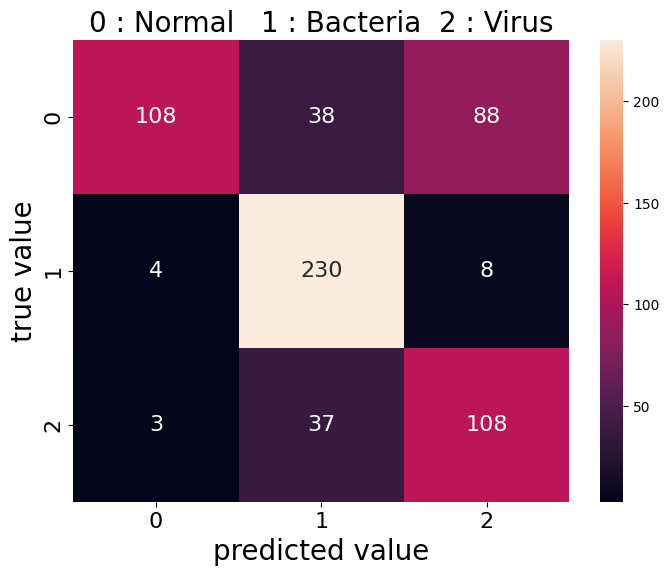

In [ ]:
mat = confusion_matrix(y_test, y_pred)
print(mat)

plt.figure(figsize=(8,6))
sns.heatmap(mat, square=False, annot=True, fmt ='d', cbar=True, annot_kws={"size": 16})
plt.title('0 : Normal   1 : Bacteria  2 : Virus', fontsize = 20)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
plt.xlabel('predicted value', fontsize = 20)
plt.ylabel('true value', fontsize = 20)
plt.show()

> ### Calculating *precision*, *recall*, *accuracy*, *F1_score* & *F2_score* for < STAGE 1 >

In [ ]:
# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Overall Accuracy: {:.4f}".format(acc))

# Precision, Recall, F1 score (per class)
precision = precision_score(y_test, y_pred, average=None)  # array of size 3
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)
f2 = fbeta_score(y_test, y_pred, beta=2, average=None)

for i, cls in enumerate(['Normal', 'Bacteria', 'Virus']):
    print("\nClass:", cls)
    print("  Precision: {:.4f}".format(precision[i]))
    print("  Recall:    {:.4f}".format(recall[i]))
    print("  F1-score:  {:.4f}".format(f1[i]))
    print("  F2-score:  {:.4f}".format(f2[i]))

# Macro / Micro averages
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f2_macro = fbeta_score(y_test, y_pred, beta=2, average='macro')

print("\nMacro Average Precision: {:.4f}".format(precision_macro))
print("Macro Average Recall: {:.4f}".format(recall_macro))
print("Macro Average F1-score: {:.4f}".format(f1_macro))
print("Macro Average F2-score: {:.4f}".format(f2_macro))

Overall Accuracy: 0.7147

Class: Normal
  Precision: 0.9391
  Recall:    0.4615
  F1-score:  0.6189
  F2-score:  0.5138

Class: Bacteria
  Precision: 0.7541
  Recall:    0.9504
  F1-score:  0.8410
  F2-score:  0.9034

Class: Virus
  Precision: 0.5294
  Recall:    0.7297
  F1-score:  0.6136
  F2-score:  0.6784

Macro Average Precision: 0.7409
Macro Average Recall: 0.7139
Macro Average F1-score: 0.6912
Macro Average F2-score: 0.6985


<a id="Stage2"></a>
+ ### STAGE 2 : Fine Training *with* Data Augmentation

<a id="Backpropagation2"></a>
> + ### Backpropagation - *Optimizer*, *Loss Function* & *Accuracy* for < STAGE 2 >

In [ ]:
lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-3,
    decay_steps=(train_data_num * epochs_stage_2) // batch_size,
    end_learning_rate=1e-5,
    power=1.0,
)

# Adam Optimizer with Learning-rate Decay
opt = Adam(learning_rate=lr_schedule)

model.compile(optimizer=opt,
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

> ### Data Augmentation Function

In [ ]:
def data_augm():
    print('Using real-time data augmentation.')
    # This will do preprocessing and realtime data augmentation:
    datagen = ImageDataGenerator(
        # randomly shift images horizontally (fraction of total width)
        width_shift_range=0.1,
        # randomly shift images vertically (fraction of total height)
        height_shift_range=0.1,
        rotation_range=10,
        horizontal_flip=True,  # Randomly flip inputs horizontally.
        # vertical_flip=True,  # Randomly flip inputs vertically.
        zoom_range=[0.9, 1.1] # Range for random zoom
    )
    return datagen

> ### Training with Data Augmentation

In [ ]:
print('With data augmentation.')
datagen = data_augm()
epochs = epochs_stage_2

# Compute quantities required for feature-wise normalization
# (std, mean, and principal components if ZCA whitening is applied).
datagen.fit(x_train[:train_data_num])

# Fit the model on the batches generated by datagen.flow().
history_data_aug = model.fit(datagen.flow(x_train[:train_data_num], y_train[:train_data_num],
                                      batch_size=batch_size),
                                      epochs=epochs,
                                      validation_data=(x_train[train_data_num:], y_train[train_data_num:]),
                                      class_weight=class_weight)

With data augmentation.
Using real-time data augmentation.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 74s 222ms/step - accuracy: 0.6713 - loss: 0.9710 - val_accuracy: 0.7116 - val_loss: 0.8724
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.6892 - loss: 0.7370 - val_accuracy: 0.6772 - val_loss: 0.8763
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.7011 - loss: 0.6846 - val_accuracy: 0.7362 - val_loss: 0.6595
Epoch 4/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 154ms/step - accuracy: 0.7244 - loss: 0.6669 - val_accuracy: 0.7333 - val_loss: 0.6789
Epoch 5/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 154ms/step - accuracy: 0.6957 - loss: 0.7059 - val_accuracy: 0.6250 - val_loss: 1.1193
Epoch 6/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.7217 - loss: 0.6565 - val_accuracy: 0.6900 - val_loss: 0.8598
Epoch 7/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 154ms/step - accuracy: 0.7235 - loss: 0.6718 - val_accuracy: 0.7421 - val_loss: 0.6478
Epoch 8/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 154ms/step - accuracy: 0.7312 - loss: 0

> ### Validation-Curve Diagrams for STAGE 2 - Training *with* Data Augmentation

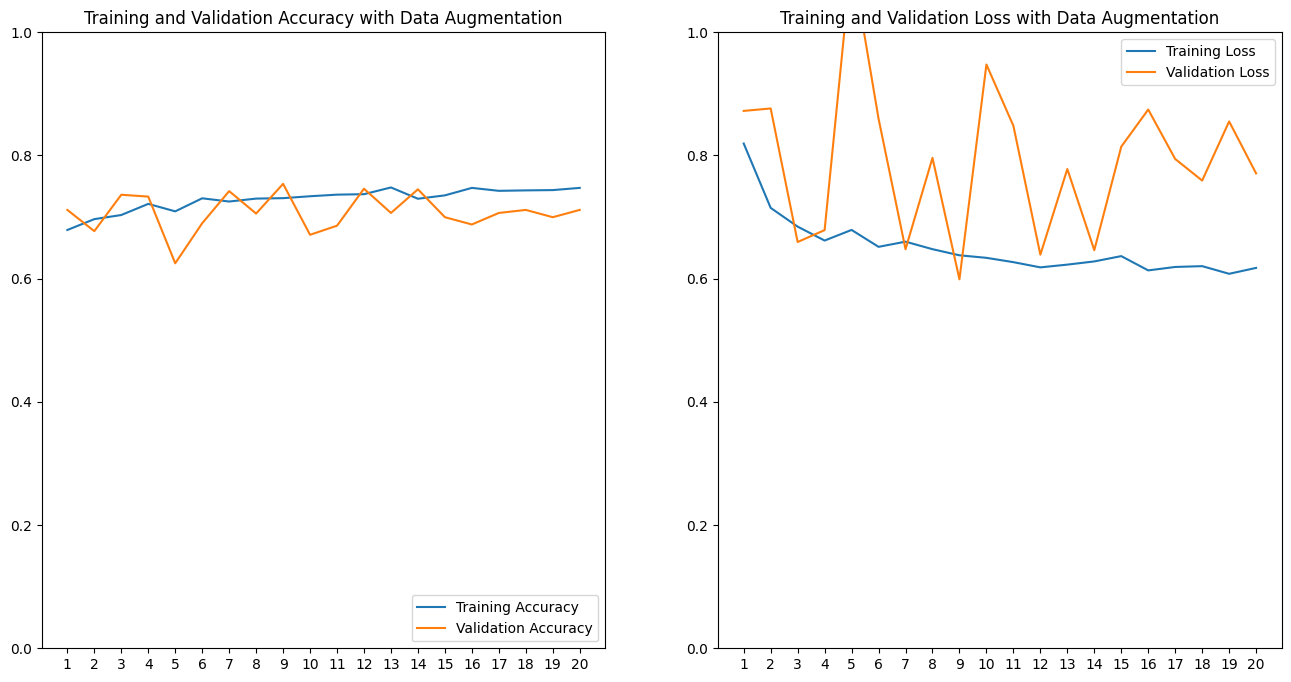

In [ ]:
acc = history_data_aug.history['accuracy']
val_acc = history_data_aug.history['val_accuracy']

loss = history_data_aug.history['loss']
val_loss = history_data_aug.history['val_loss']

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Accuracy with Data Augmentation')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Loss with Data Augmentation')
plt.show()

> ### Evaluation with Test Dataset for < STAGE 2 >

In [ ]:
# Score trained model.
loss, acc = model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 341ms/step - accuracy: 0.7780 - loss: 0.6443
Test loss: 0.6344814300537109
Test accuracy: 0.7820512652397156


In [ ]:
# 得到預測機率
y_pred_prob = model.predict(x_test)  # shape: (num_samples, 3)

# 取最大機率的索引 -> 預測類別
y_pred = np.argmax(y_pred_prob, axis=1)  # shape: (num_samples,)

# 確認 y_test 和 y_pred
print("前 10 筆預測:", y_pred[:10])
print("前 10 筆真實:", y_test[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 398ms/step
前 10 筆預測: [2 0 1 0 2 1 2 1 2 0]
前 10 筆真實: [2 0 1 0 2 1 2 1 2 0]


> ### Confusion Matrix for < STAGE 2 >

[[197  12  25]
 [ 42 196   4]
 [ 24  29  95]]


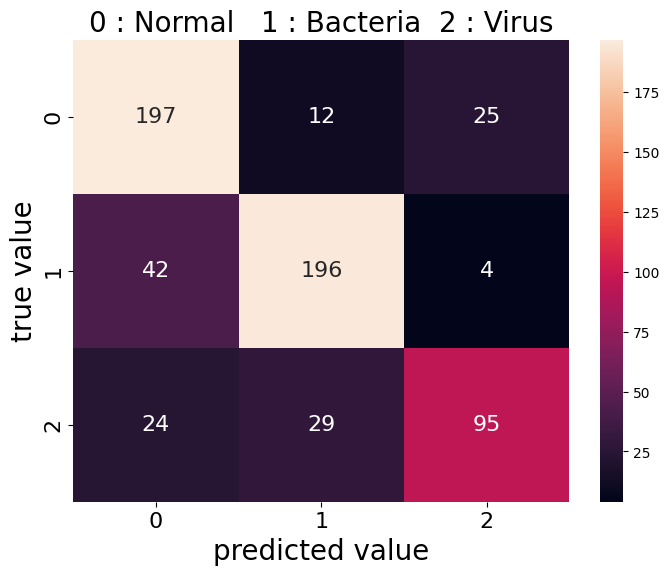

In [ ]:
mat = confusion_matrix(y_test, y_pred)
print(mat)

plt.figure(figsize=(8,6))
sns.heatmap(mat, square=False, annot=True, fmt ='d', cbar=True, annot_kws={"size": 16})
plt.title('0 : Normal   1 : Bacteria  2 : Virus', fontsize = 20)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
plt.xlabel('predicted value', fontsize = 20)
plt.ylabel('true value', fontsize = 20)
plt.show()

### Calculating *precision*, *recall*, *accuracy*, *F1_score* & *F2_score* for < STAGE 2 >

In [ ]:
# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Overall Accuracy: {:.4f}".format(acc))

# Precision, Recall, F1 score (per class)
precision = precision_score(y_test, y_pred, average=None)  # array of size 3
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)
f2 = fbeta_score(y_test, y_pred, beta=2, average=None)

for i, cls in enumerate(['Normal', 'Bacteria', 'Virus']):
    print("\nClass:", cls)
    print("  Precision: {:.4f}".format(precision[i]))
    print("  Recall:    {:.4f}".format(recall[i]))
    print("  F1-score:  {:.4f}".format(f1[i]))
    print("  F2-score:  {:.4f}".format(f2[i]))

# Macro / Micro averages
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f2_macro = fbeta_score(y_test, y_pred, beta=2, average='macro')

print("\nMacro Average Precision: {:.4f}".format(precision_macro))
print("Macro Average Recall: {:.4f}".format(recall_macro))
print("Macro Average F1-score: {:.4f}".format(f1_macro))
print("Macro Average F2-score: {:.4f}".format(f2_macro))

Overall Accuracy: 0.7821

Class: Normal
  Precision: 0.7490
  Recall:    0.8419
  F1-score:  0.7928
  F2-score:  0.8215

Class: Bacteria
  Precision: 0.8270
  Recall:    0.8099
  F1-score:  0.8184
  F2-score:  0.8133

Class: Virus
  Precision: 0.7661
  Recall:    0.6419
  F1-score:  0.6985
  F2-score:  0.6634

Macro Average Precision: 0.7807
Macro Average Recall: 0.7646
Macro Average F1-score: 0.7699
Macro Average F2-score: 0.7661


<a id="Stage3"></a>
+ ### STAGE 3 : UnFreeze Layer

In [ ]:
for layer in base_model.layers[:unfreeze]:
    layer.trainable = False
for layer in base_model.layers[unfreeze:]:
    layer.trainable = True

lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-5,
    decay_steps=(train_data_num * epochs_stage_1) // batch_size,
    end_learning_rate=1e-7,
    power=1.0,
)

# Adam Optimizer with Learning-rate Decay
opt = Adam(learning_rate=lr_schedule)

model.compile(
    optimizer=opt,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [ ]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_4 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_4 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_8              │ (None, 7, 7, 256)      │       339,456 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_9              │ (None, 7, 7, 128)      │        35,200 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,634,563 (10.05 MB)

 Trainable params: 2,000,707 (7.63 MB)

 Non-trainable params: 633,856 (2.42 MB)

In [ ]:
epochs = epochs_stage_3

# Fit the model on the batches generated by datagen.flow().
history_unfreeze = model.fit(datagen.flow(x_train[:train_data_num], y_train[:train_data_num],
                                      batch_size=batch_size),
                                      epochs=epochs,
                                      validation_data=(x_train[train_data_num:], y_train[train_data_num:]),
                                      class_weight=class_weight)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 83s 235ms/step - accuracy: 0.6179 - loss: 1.0642 - val_accuracy: 0.2539 - val_loss: 2.7674
Epoch 2/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.7293 - loss: 0.6607 - val_accuracy: 0.2539 - val_loss: 3.2646
Epoch 3/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 154ms/step - accuracy: 0.7356 - loss: 0.6383 - val_accuracy: 0.2539 - val_loss: 2.6946
Epoch 4/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.7431 - loss: 0.6169 - val_accuracy: 0.3209 - val_loss: 1.9840
Epoch 5/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.7387 - loss: 0.6254 - val_accuracy: 0.2470 - val_loss: 2.9171
Epoch 6/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 40s 154ms/step - accuracy: 0.7492 - loss: 0.5929 - val_accuracy: 0.2343 - val_loss: 2.4932
Epoch 7/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.7527 - loss: 0.5997 - val_accuracy: 0.2549 - val_loss: 2.8025
Epoch 8/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 155ms/step - accuracy: 0.7454 - loss: 0

> ### Validation-Curve Diagrams for STAGE 3 - UnFreeze Layer


In [ ]:
acc = history_unfreeze.history['accuracy']
val_acc = history_unfreeze.history['val_accuracy']

loss = history_unfreeze.history['loss']
val_loss = history_unfreeze.history['val_loss']

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Accuracy with Data Augmentation')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Loss with Data Augmentation')
plt.show()

> ### Evaluation with Test Dataset for < STAGE 3 >

In [ ]:
# Score trained model.
loss, acc = model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

In [186]:
# 得到預測機率
y_pred_prob = model.predict(x_test)  # shape: (num_samples, 3)

# 取最大機率的索引 -> 預測類別
y_pred = np.argmax(y_pred_prob, axis=1)  # shape: (num_samples,)

# 確認 y_test 和 y_pred
print("前 10 筆預測:", y_pred[:10])
print("前 10 筆真實:", y_test[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 403ms/step
前 10 筆預測: [2 0 1 0 2 1 2 1 2 2]
前 10 筆真實: [2 0 1 0 2 1 2 1 2 0]


> ### Confusion Matrix for < STAGE 3 >

[[202   6  26]
 [ 29 213   0]
 [ 18  32  98]]


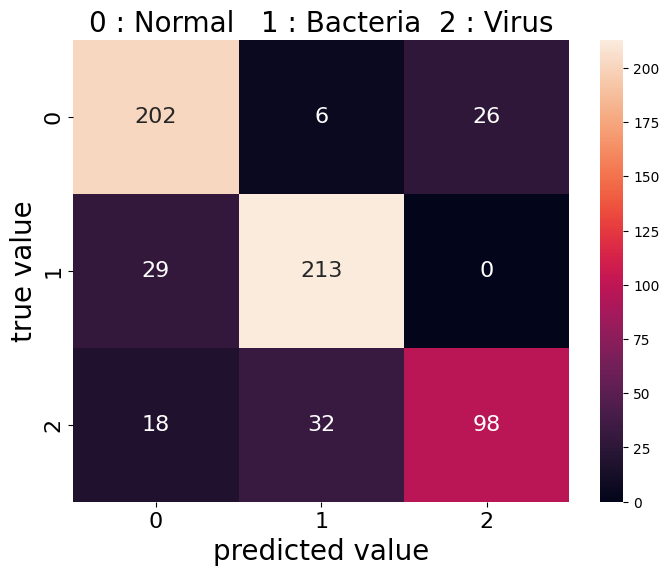

In [187]:
mat = confusion_matrix(y_test, y_pred)
print(mat)

plt.figure(figsize=(8,6))
sns.heatmap(mat, square=False, annot=True, fmt ='d', cbar=True, annot_kws={"size": 16})
plt.title('0 : Normal   1 : Bacteria  2 : Virus', fontsize = 20)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
plt.xlabel('predicted value', fontsize = 20)
plt.ylabel('true value', fontsize = 20)
plt.show()

### Calculating *precision*, *recall*, *accuracy*, *F1_score* & *F2_score* for < STAGE 3 >

In [188]:
# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Overall Accuracy: {:.4f}".format(acc))

# Precision, Recall, F1 score (per class)
precision = precision_score(y_test, y_pred, average=None)  # array of size 3
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)
f2 = fbeta_score(y_test, y_pred, beta=2, average=None)

for i, cls in enumerate(['Normal', 'Bacteria', 'Virus']):
    print("\nClass:", cls)
    print("  Precision: {:.4f}".format(precision[i]))
    print("  Recall:    {:.4f}".format(recall[i]))
    print("  F1-score:  {:.4f}".format(f1[i]))
    print("  F2-score:  {:.4f}".format(f2[i]))

# Macro / Micro averages
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f2_macro = fbeta_score(y_test, y_pred, beta=2, average='macro')

print("\nMacro Average Precision: {:.4f}".format(precision_macro))
print("Macro Average Recall: {:.4f}".format(recall_macro))
print("Macro Average F1-score: {:.4f}".format(f1_macro))
print("Macro Average F2-score: {:.4f}".format(f2_macro))

Overall Accuracy: 0.8221

Class: Normal
  Precision: 0.8112
  Recall:    0.8632
  F1-score:  0.8364
  F2-score:  0.8523

Class: Bacteria
  Precision: 0.8486
  Recall:    0.8802
  F1-score:  0.8641
  F2-score:  0.8737

Class: Virus
  Precision: 0.7903
  Recall:    0.6622
  F1-score:  0.7206
  F2-score:  0.6844

Macro Average Precision: 0.8167
Macro Average Recall: 0.8019
Macro Average F1-score: 0.8070
Macro Average F2-score: 0.8034


<a id="Result1"></a>
## Results(A)
> + 由以上結果可知：經過 30 epochs (i.e., Stage 1 + Stage 2) 的訓練，**Recall** 值接近 100%；這代表預測模型的 false-negative 誤判部分 (亦即，將 Pneumonia 誤判成 Normal 的狀況) 將會下降趨近 0。
> + 然而， **F1 score** 仍然還有改進的空間；這是因為 false-positive 誤診部分 (亦即，將 Normal 誤判成 Pneumonia 的狀況) 造成 **Precision** 的精確值偏低的緣故。
> + 請想想看，如何改進模型或調校預測模型參數 (hyperparameters)，進而能夠使其 **F1 score** 數值上升。  Good luck！

以下將 From-Coarse-to-Fine 全程訓練過程的 Learning Curves 繪製如下，做為參考：

In [189]:
acc_total = history_no_data_aug.history['accuracy'] + history_data_aug.history['accuracy'] + history_unfreeze.history['accuracy']
val_acc_total = history_no_data_aug.history['val_accuracy'] + history_data_aug.history['val_accuracy'] + history_unfreeze.history['val_accuracy']

loss_total = history_no_data_aug.history['loss'] + history_data_aug.history['loss'] + history_unfreeze.history['loss']
val_loss_total = history_no_data_aug.history['val_loss'] + history_data_aug.history['val_loss'] + history_unfreeze.history['val_loss']

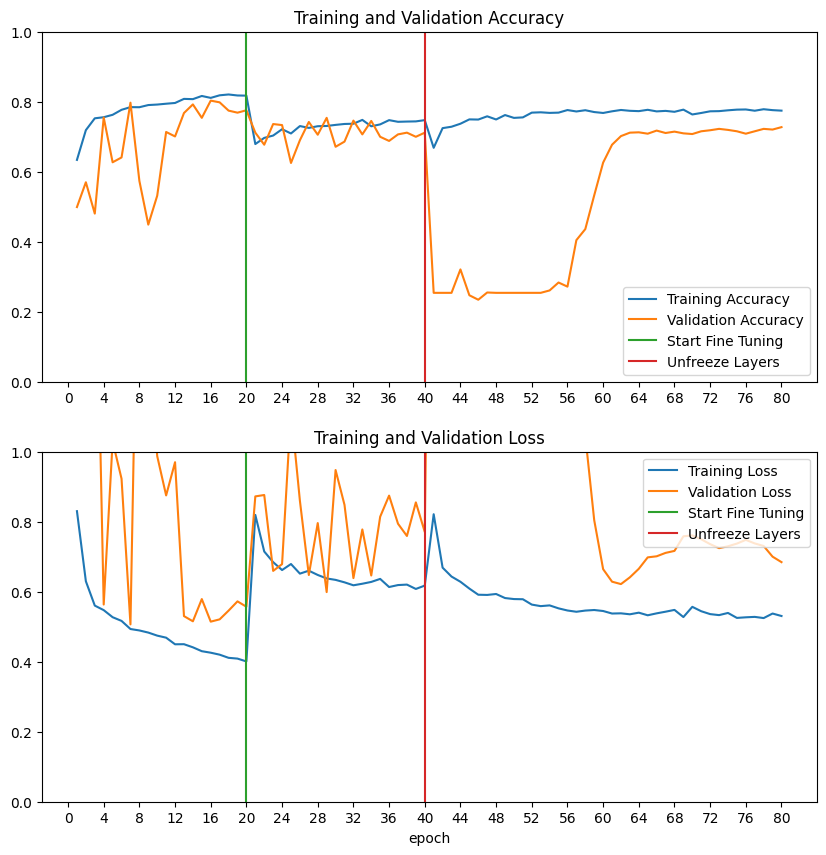

In [190]:
initial_epochs = epochs_stage_1
second_epochs = epochs_stage_1 + epochs_stage_2
total_epochs = epochs_stage_1 + epochs_stage_2 + epochs_stage_3
epochs_range = range(1, total_epochs + 1)

plt.figure(figsize=(10, 10))
plt.subplot(2, 1, 1)
plt.plot(epochs_range, acc_total, label='Training Accuracy')
plt.plot(epochs_range, val_acc_total, label='Validation Accuracy')
plt.ylim([0, 1])
plt.xticks(range(0,total_epochs+1,4))
plt.plot([initial_epochs,initial_epochs],
          plt.ylim(), label='Start Fine Tuning')
plt.plot([second_epochs,second_epochs],
          plt.ylim(), label='Unfreeze Layers')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(epochs_range, loss_total, label='Training Loss')
plt.plot(epochs_range, val_loss_total, label='Validation Loss')
plt.ylim([0, 1])
plt.xticks(range(0,total_epochs+1,4))
plt.plot([initial_epochs,initial_epochs],
         plt.ylim(), label='Start Fine Tuning')
plt.plot([second_epochs,second_epochs],
          plt.ylim(), label='Unfreeze Layers')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

<a id="SavingEntireModel"></a>
## 6. Saving the Entire Model

In [191]:
model.save("MobileNetV2_model.keras")

In [192]:
# Reload the Keras model (.keras format)
MobileNetV2_model = tf.keras.models.load_model('MobileNetV2_model.keras')

# Show the model architecture
MobileNetV2_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_4 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_4 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_8              │ (None, 7, 7, 256)      │       339,456 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_9              │ (None, 7, 7, 128)      │        35,200 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,635,978 (25.31 MB)

 Trainable params: 2,000,707 (7.63 MB)

 Non-trainable params: 633,856 (2.42 MB)

 Optimizer params: 4,001,415 (15.26 MB)

In [193]:
# Evaluate the restored model
loss, acc = MobileNetV2_model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 342ms/step - accuracy: 0.8227 - loss: 0.5215
Test loss: 0.5178055167198181
Test accuracy: 0.8221153616905212


In [194]:
# submission = pd.concat([pd.Series(range(1,(len(pred)+1)),name = "ImageId"),preds],axis = 1)
data_subm = {'ImageId': pd.Series(range(1,(len(y_pred)+1))), 'Prediction': y_pred}
submission = pd.DataFrame(data_subm)
submission = submission.applymap(str)

submission.to_csv("submission.csv",index=False)

/tmp/ipython-input-2856244980.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  submission = submission.applymap(str)




---





---



<a id='MobileNetV2'></a>
## (B) **ResNet50** by *tf.keras*

<a id="Forwardpropagation"></a>
+ ### Forward Propagation - with Batch Normalization and Dropout


In [ ]:
# ---- Base Model: ResNet50 ----
base_model = keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False


# ---- Model Input ----
inputs = keras.layers.Input(shape=(224, 224, 3))

# ResNet50 前處理
x = keras.applications.resnet50.preprocess_input(inputs)

# Base Model
x = base_model(x)


# ---- 你的 CNN 強化層（改用 Conv2D，因 ResNet 不適用 SeparableConv2D）----
x = Conv2D(256, (3,3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Conv2D(128, (3,3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = MaxPooling2D((2,2))(x)

# ---- GAP + Dropout ----
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)


# ---- Output Layer ----
outputs = Dense(3, activation="softmax")(x)

# ---- Final Model ----
model = keras.Model(inputs, outputs)

<a id="ModelSummary"></a>
+ ### Model Summary & Plotting the Model

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 7, 7, 256) │  4,718,848 │ resnet50[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 256) │      1,024 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 128) │    295,040 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 128) │        512 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 7, 7, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 3, 3, 128) │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        387 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,603,523 (109.11 MB)

 Trainable params: 5,015,043 (19.13 MB)

 Non-trainable params: 23,588,480 (89.98 MB)

<a id="StartTraining"></a>
## Start Training with Data Augmentation

<a id="SettingHyperparameters"></a>
+ ### Setting Hyperparameters for Training Process
>+ 由於 validation dataset 只有 16 筆影像資料 (太少了些)，因此，直接將 training datasets (5216 images) 分割出 4200 筆的 training 資料 (80.5% 資料量)，其餘的 1016 張 X-ray 影像資料做為 validation 資料集。
>+ **[ Learning-Rate Decay ] : basic learning rate = 0.001**
    + 在 STAGE 1 中，設定 basic learning rate 的 1/10 為 decay rate，取 epoch 數為 10 時，每個 epoch 的 GPU 運算時間約為 20 秒。
    + 在 STAGE 2 中，設定 learning_rate 為 basic learning rate 的 1/10 (decay rate =  learning_rate/100)，取 epoch 數為 20，每個 epoch 的 GPU 運算時間約為 45 秒。

In [ ]:
batch_size = 16
epochs_stage_1 = 25
epochs_stage_2 = 25
epochs_stage_3 = 40
train_data_num = 4200
unfreeze = 140
class_weight = {0: 1.2, 1: 1.0, 2: 1.1}

<a id="Stage1"></a>
+ ### STAGE 1 : Coarse Training *without* Data Augmentation

<a id="Backpropagation1"></a>
> + ### Backpropagation - *Optimizer*, *Loss Function* & *Accuracy* for < STAGE 1 >

In [ ]:
lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-2,
    decay_steps=(train_data_num * epochs_stage_1) // batch_size,
    end_learning_rate=1e-5,
    power=1.0,
)

# Adam Optimizer with Learning-rate Decay
opt = Adam(learning_rate=lr_schedule)

model.compile(optimizer=opt,
              loss = tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
## data_augmentation = False
print('Not using data augmentation.')
epochs = epochs_stage_1


history_no_data_aug = model.fit(x_train[:train_data_num], y_train[:train_data_num],
                               batch_size=batch_size,
                               epochs=epochs,
                               validation_data=(x_train[train_data_num:], y_train[train_data_num:]),
                               class_weight=class_weight,
                               shuffle=False)

Not using data augmentation.
Epoch 1/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 35s 81ms/step - accuracy: 0.4938 - loss: 1.2653 - val_accuracy: 0.6654 - val_loss: 0.7153
Epoch 2/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.6509 - loss: 0.7658 - val_accuracy: 0.3445 - val_loss: 1.7353
Epoch 3/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.6718 - loss: 0.7153 - val_accuracy: 0.7283 - val_loss: 0.5693
Epoch 4/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.6991 - loss: 0.6740 - val_accuracy: 0.6152 - val_loss: 0.9756
Epoch 5/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.7165 - loss: 0.6548 - val_accuracy: 0.5335 - val_loss: 1.3338
Epoch 6/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.7312 - loss: 0.6349 - val_accuracy: 0.5374 - val_loss: 1.5228
Epoch 7/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.7411 - loss: 0.6080 - val_accuracy: 0.5965 - val_loss: 0.8875
Epoch 8/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.

> ### Validation-Curve Diagrams for STAGE 1 - Training without Data Augmentation

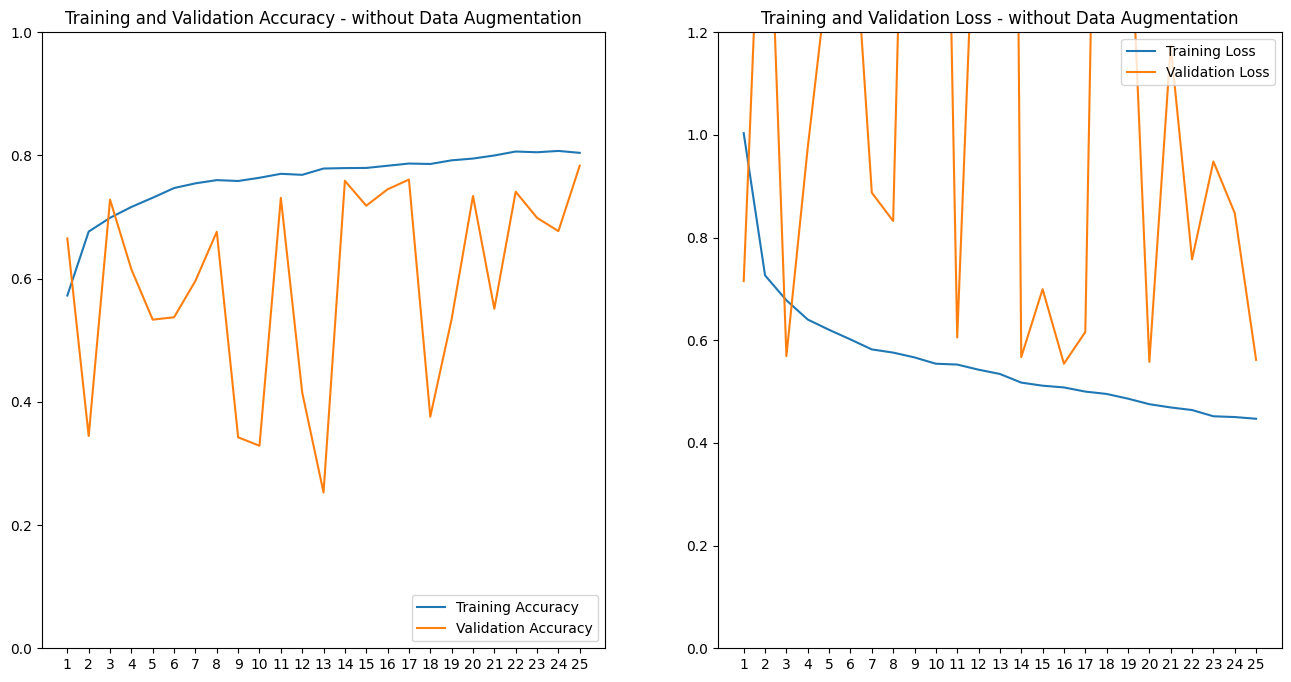

In [ ]:
acc = history_no_data_aug.history['accuracy']
val_acc = history_no_data_aug.history['val_accuracy']

loss = history_no_data_aug.history['loss']
val_loss = history_no_data_aug.history['val_loss']

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Accuracy - without Data Augmentation')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylim(0, 1.2)
plt.xticks(epochs_range)
plt.title('Training and Validation Loss - without Data Augmentation')
plt.show()

> ### Evaluation for Test Datasets in < STAGE 1 >

In [ ]:
# Score trained model.
loss, acc = model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.7397 - loss: 1.2253
Test loss: 1.1147387027740479
Test accuracy: 0.7564102411270142


In [ ]:
# 得到預測機率
y_pred_prob = model.predict(x_test)  # shape: (num_samples, 3)

# 取最大機率的索引 -> 預測類別
y_pred = np.argmax(y_pred_prob, axis=1)  # shape: (num_samples,)

# 確認 y_test 和 y_pred
print("前 10 筆預測:", y_pred[:10])
print("前 10 筆真實:", y_test[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 250ms/step
前 10 筆預測: [2 0 1 1 2 1 2 1 2 2]
前 10 筆真實: [2 0 1 0 2 1 2 1 2 0]


> ### Confusion Matrix for < STAGE 1 >

[[140  15  79]
 [  5 223  14]
 [  6  33 109]]


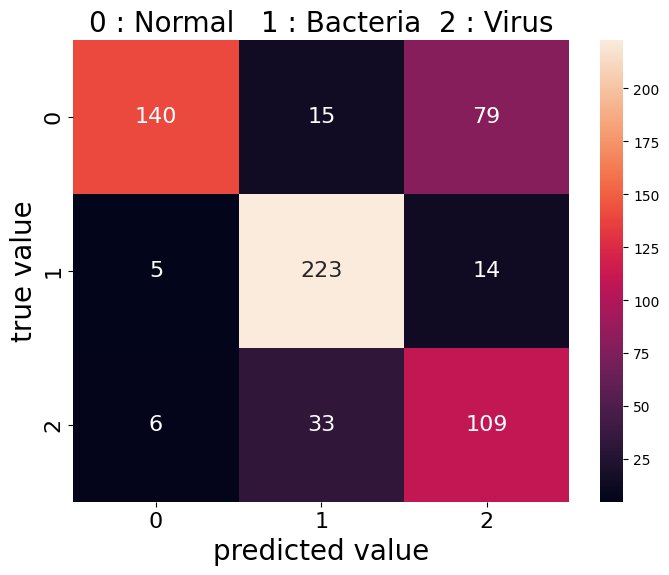

In [ ]:
mat = confusion_matrix(y_test, y_pred)
print(mat)

plt.figure(figsize=(8,6))
sns.heatmap(mat, square=False, annot=True, fmt ='d', cbar=True, annot_kws={"size": 16})
plt.title('0 : Normal   1 : Bacteria  2 : Virus', fontsize = 20)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
plt.xlabel('predicted value', fontsize = 20)
plt.ylabel('true value', fontsize = 20)
plt.show()

> ### Calculating *precision*, *recall*, *accuracy*, *F1_score* & *F2_score* for < STAGE 1 >

In [ ]:
# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Overall Accuracy: {:.4f}".format(acc))

# Precision, Recall, F1 score (per class)
precision = precision_score(y_test, y_pred, average=None)  # array of size 3
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)
f2 = fbeta_score(y_test, y_pred, beta=2, average=None)

for i, cls in enumerate(['Normal', 'Bacteria', 'Virus']):
    print("\nClass:", cls)
    print("  Precision: {:.4f}".format(precision[i]))
    print("  Recall:    {:.4f}".format(recall[i]))
    print("  F1-score:  {:.4f}".format(f1[i]))
    print("  F2-score:  {:.4f}".format(f2[i]))

# Macro / Micro averages
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f2_macro = fbeta_score(y_test, y_pred, beta=2, average='macro')

print("\nMacro Average Precision: {:.4f}".format(precision_macro))
print("Macro Average Recall: {:.4f}".format(recall_macro))
print("Macro Average F1-score: {:.4f}".format(f1_macro))
print("Macro Average F2-score: {:.4f}".format(f2_macro))

Overall Accuracy: 0.7564

Class: Normal
  Precision: 0.9272
  Recall:    0.5983
  F1-score:  0.7273
  F2-score:  0.6440

Class: Bacteria
  Precision: 0.8229
  Recall:    0.9215
  F1-score:  0.8694
  F2-score:  0.8999

Class: Virus
  Precision: 0.5396
  Recall:    0.7365
  F1-score:  0.6229
  F2-score:  0.6864

Macro Average Precision: 0.7632
Macro Average Recall: 0.7521
Macro Average F1-score: 0.7398
Macro Average F2-score: 0.7434


<a id="Stage2"></a>
+ ### STAGE 2 : Fine Training *with* Data Augmentation

<a id="Backpropagation2"></a>
> + ### Backpropagation - *Optimizer*, *Loss Function* & *Accuracy* for < STAGE 2 >

In [ ]:
lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-3,
    decay_steps=(train_data_num * epochs_stage_2) // batch_size,
    end_learning_rate=1e-5,
    power=1.0,
)

# Adam Optimizer with Learning-rate Decay
opt = Adam(learning_rate=lr_schedule)

model.compile(optimizer=opt,
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

> ### Data Augmentation Function

In [ ]:
def data_augm():
    print('Using real-time data augmentation.')
    # This will do preprocessing and realtime data augmentation:
    datagen = ImageDataGenerator(
        # randomly shift images horizontally (fraction of total width)
        width_shift_range=0.1,
        # randomly shift images vertically (fraction of total height)
        height_shift_range=0.1,
        rotation_range=10,
        horizontal_flip=True,  # Randomly flip inputs horizontally.
        # vertical_flip=True,  # Randomly flip inputs vertically.
        zoom_range=[0.9, 1.1] # Range for random zoom
    )
    return datagen

> ### Training with Data Augmentation

In [ ]:
print('With data augmentation.')
datagen = data_augm()
epochs = epochs_stage_2

# Compute quantities required for feature-wise normalization
# (std, mean, and principal components if ZCA whitening is applied).
datagen.fit(x_train[:train_data_num])

# Fit the model on the batches generated by datagen.flow().
history_data_aug = model.fit(datagen.flow(x_train[:train_data_num], y_train[:train_data_num],
                                      batch_size=batch_size),
                                      epochs=epochs,
                                      validation_data=(x_train[train_data_num:], y_train[train_data_num:]),
                                      class_weight=class_weight)

With data augmentation.
Using real-time data augmentation.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 68s 209ms/step - accuracy: 0.6620 - loss: 0.9229 - val_accuracy: 0.7884 - val_loss: 0.4924
Epoch 2/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 42s 158ms/step - accuracy: 0.6709 - loss: 0.7967 - val_accuracy: 0.7165 - val_loss: 0.6877
Epoch 3/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 157ms/step - accuracy: 0.7022 - loss: 0.7345 - val_accuracy: 0.7136 - val_loss: 0.6230
Epoch 4/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 157ms/step - accuracy: 0.7147 - loss: 0.7208 - val_accuracy: 0.7805 - val_loss: 0.5157
Epoch 5/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 42s 158ms/step - accuracy: 0.6916 - loss: 0.7199 - val_accuracy: 0.7195 - val_loss: 0.7001
Epoch 6/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 42s 158ms/step - accuracy: 0.6935 - loss: 0.7405 - val_accuracy: 0.3927 - val_loss: 2.1227
Epoch 7/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 157ms/step - accuracy: 0.7193 - loss: 0.7056 - val_accuracy: 0.7067 - val_loss: 0.6363
Epoch 8/25
263/263 ━━━━━━━━━━━━━━━━━━━━ 42s 158ms/step - accuracy: 0.7158 - loss: 0

> ### Validation-Curve Diagrams for STAGE 2 - Training *with* Data Augmentation

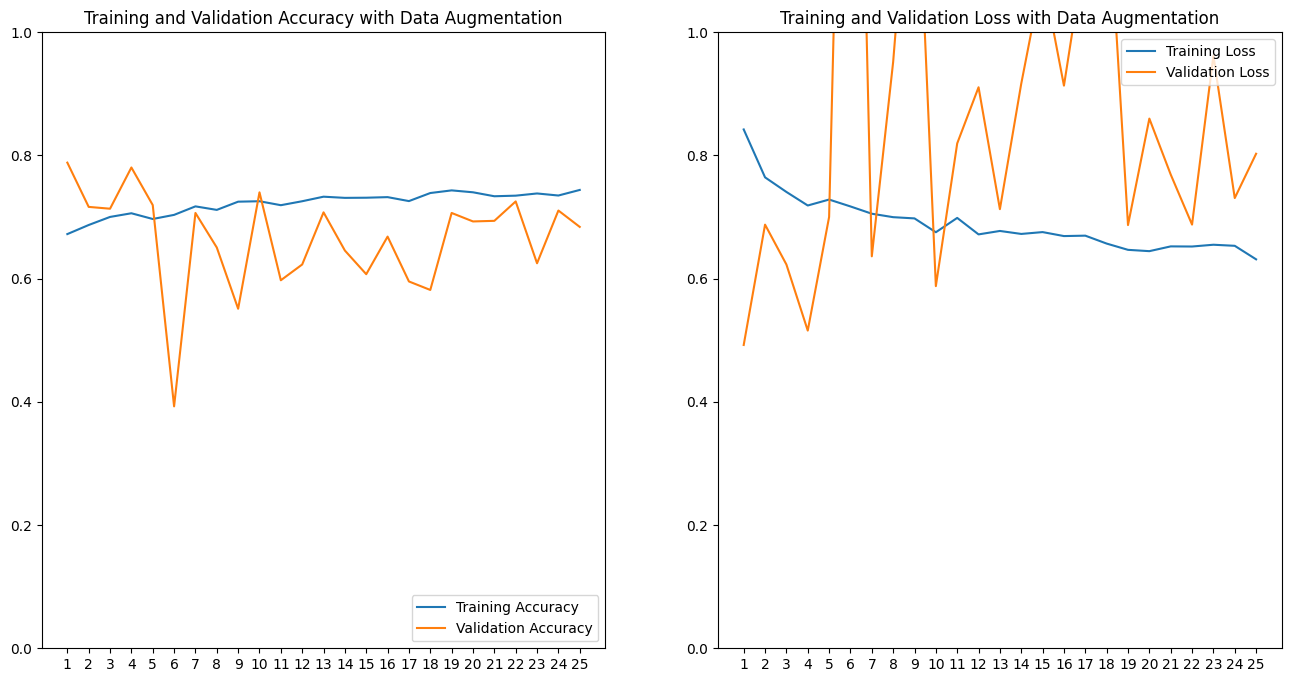

In [ ]:
acc = history_data_aug.history['accuracy']
val_acc = history_data_aug.history['val_accuracy']

loss = history_data_aug.history['loss']
val_loss = history_data_aug.history['val_loss']

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Accuracy with Data Augmentation')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Loss with Data Augmentation')
plt.show()

> ### Evaluation with Test Dataset for < STAGE 2 >

In [ ]:
# Score trained model.
loss, acc = model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 155ms/step - accuracy: 0.7904 - loss: 0.5719
Test loss: 0.5788840055465698
Test accuracy: 0.8028846383094788


In [ ]:
# 得到預測機率
y_pred_prob = model.predict(x_test)  # shape: (num_samples, 3)

# 取最大機率的索引 -> 預測類別
y_pred = np.argmax(y_pred_prob, axis=1)  # shape: (num_samples,)

# 確認 y_test 和 y_pred
print("前 10 筆預測:", y_pred[:10])
print("前 10 筆真實:", y_test[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 254ms/step
前 10 筆預測: [2 0 1 0 2 2 2 1 2 0]
前 10 筆真實: [2 0 1 0 2 1 2 1 2 0]


> ### Confusion Matrix for < STAGE 2 >

[[215   5  14]
 [ 35 191  16]
 [ 35  18  95]]


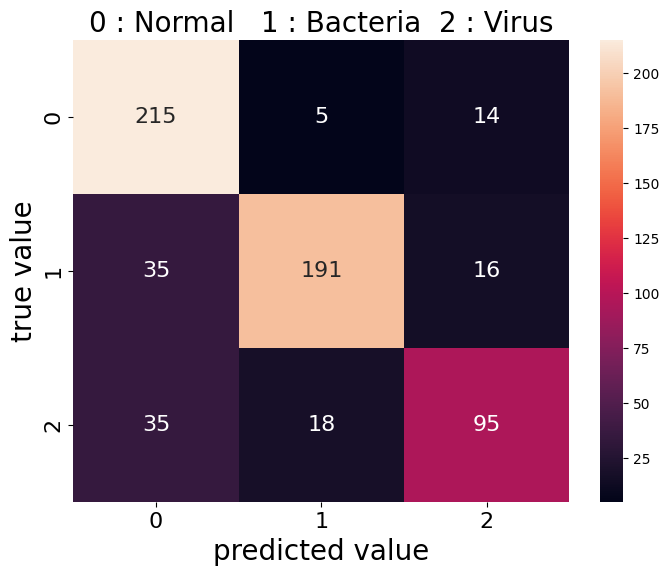

In [ ]:
mat = confusion_matrix(y_test, y_pred)
print(mat)

plt.figure(figsize=(8,6))
sns.heatmap(mat, square=False, annot=True, fmt ='d', cbar=True, annot_kws={"size": 16})
plt.title('0 : Normal   1 : Bacteria  2 : Virus', fontsize = 20)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
plt.xlabel('predicted value', fontsize = 20)
plt.ylabel('true value', fontsize = 20)
plt.show()

### Calculating *precision*, *recall*, *accuracy*, *F1_score* & *F2_score* for < STAGE 2 >

In [ ]:
# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Overall Accuracy: {:.4f}".format(acc))

# Precision, Recall, F1 score (per class)
precision = precision_score(y_test, y_pred, average=None)  # array of size 3
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)
f2 = fbeta_score(y_test, y_pred, beta=2, average=None)

for i, cls in enumerate(['Normal', 'Bacteria', 'Virus']):
    print("\nClass:", cls)
    print("  Precision: {:.4f}".format(precision[i]))
    print("  Recall:    {:.4f}".format(recall[i]))
    print("  F1-score:  {:.4f}".format(f1[i]))
    print("  F2-score:  {:.4f}".format(f2[i]))

# Macro / Micro averages
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f2_macro = fbeta_score(y_test, y_pred, beta=2, average='macro')

print("\nMacro Average Precision: {:.4f}".format(precision_macro))
print("Macro Average Recall: {:.4f}".format(recall_macro))
print("Macro Average F1-score: {:.4f}".format(f1_macro))
print("Macro Average F2-score: {:.4f}".format(f2_macro))

Overall Accuracy: 0.8029

Class: Normal
  Precision: 0.7544
  Recall:    0.9188
  F1-score:  0.8285
  F2-score:  0.8804

Class: Bacteria
  Precision: 0.8925
  Recall:    0.7893
  F1-score:  0.8377
  F2-score:  0.8080

Class: Virus
  Precision: 0.7600
  Recall:    0.6419
  F1-score:  0.6960
  F2-score:  0.6625

Macro Average Precision: 0.8023
Macro Average Recall: 0.7833
Macro Average F1-score: 0.7874
Macro Average F2-score: 0.7836


<a id="Stage3"></a>
+ ### STAGE 3 : UnFreeze Layer

In [ ]:
for layer in base_model.layers[:unfreeze]:
    layer.trainable = False
for layer in base_model.layers[unfreeze:]:
    layer.trainable = True

lr_schedule = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=1e-5,
    decay_steps=(train_data_num * epochs_stage_1) // batch_size,
    end_learning_rate=1e-7,
    power=1.0,
)

# Adam Optimizer with Learning-rate Decay
opt = Adam(learning_rate=lr_schedule)

model.compile(
    optimizer=opt,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 7, 7, 256) │  4,718,848 │ resnet50[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 256) │      1,024 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 128) │    295,040 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 128) │        512 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 7, 7, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 3, 3, 128) │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        387 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,603,523 (109.11 MB)

 Trainable params: 19,993,091 (76.27 MB)

 Non-trainable params: 8,610,432 (32.85 MB)

In [ ]:
epochs = epochs_stage_3

# Fit the model on the batches generated by datagen.flow().
history_unfreeze = model.fit(datagen.flow(x_train[:train_data_num], y_train[:train_data_num],
                                      batch_size=batch_size),
                                      epochs=epochs,
                                      validation_data=(x_train[train_data_num:], y_train[train_data_num:]),
                                      class_weight=class_weight)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 79s 217ms/step - accuracy: 0.5987 - loss: 1.0680 - val_accuracy: 0.3081 - val_loss: 2.3679
Epoch 2/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 158ms/step - accuracy: 0.7210 - loss: 0.6854 - val_accuracy: 0.6260 - val_loss: 1.1218
Epoch 3/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 156ms/step - accuracy: 0.7333 - loss: 0.6620 - val_accuracy: 0.7372 - val_loss: 0.5861
Epoch 4/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 157ms/step - accuracy: 0.7446 - loss: 0.6529 - val_accuracy: 0.7195 - val_loss: 0.6536
Epoch 5/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 157ms/step - accuracy: 0.7561 - loss: 0.6130 - val_accuracy: 0.6988 - val_loss: 0.7841
Epoch 6/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 42s 158ms/step - accuracy: 0.7482 - loss: 0.6083 - val_accuracy: 0.5994 - val_loss: 1.0454
Epoch 7/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 42s 158ms/step - accuracy: 0.7633 - loss: 0.5902 - val_accuracy: 0.7648 - val_loss: 0.5534
Epoch 8/40
263/263 ━━━━━━━━━━━━━━━━━━━━ 42s 160ms/step - accuracy: 0.7735 - loss: 0

> ### Validation-Curve Diagrams for STAGE 3 - UnFreeze Layer


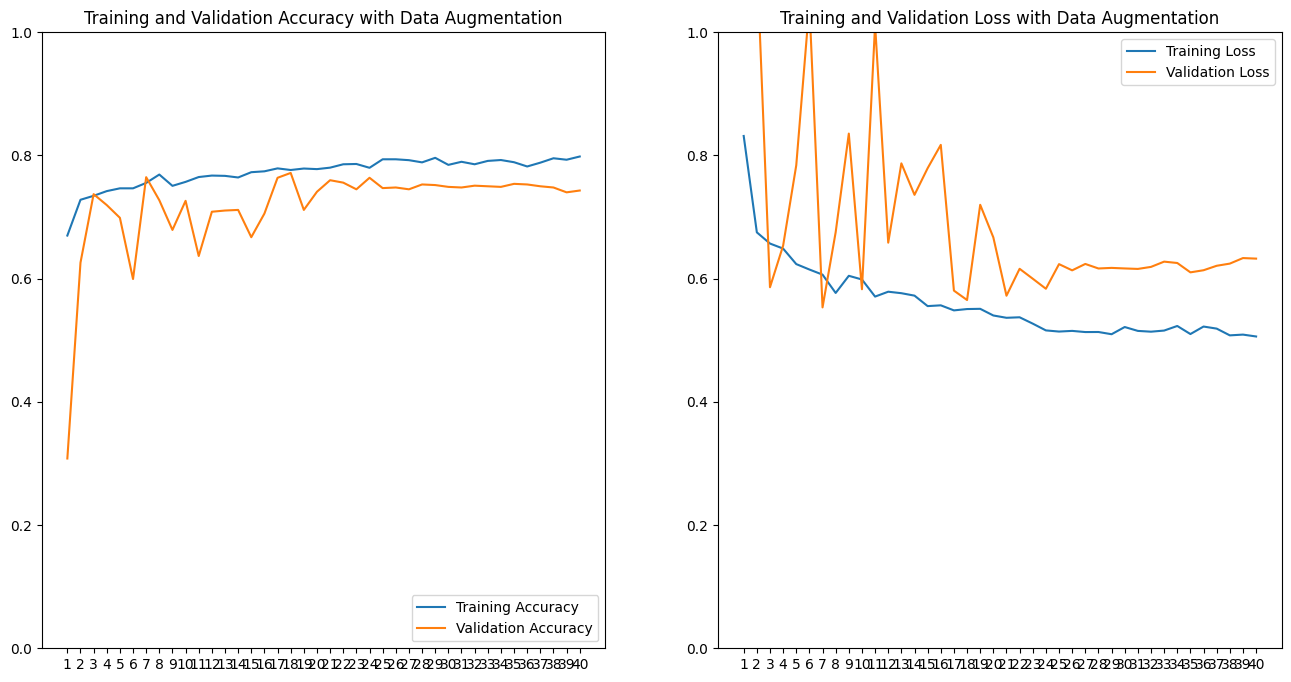

In [ ]:
acc = history_unfreeze.history['accuracy']
val_acc = history_unfreeze.history['val_accuracy']

loss = history_unfreeze.history['loss']
val_loss = history_unfreeze.history['val_loss']

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Accuracy with Data Augmentation')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylim(0, 1)
plt.xticks(epochs_range)
plt.title('Training and Validation Loss with Data Augmentation')
plt.show()

> ### Evaluation with Test Dataset for < STAGE 3 >

In [ ]:
# Score trained model.
loss, acc = model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 169ms/step - accuracy: 0.8060 - loss: 0.5845
Test loss: 0.5223252177238464
Test accuracy: 0.8221153616905212


In [ ]:
# 得到預測機率
y_pred_prob = model.predict(x_test)  # shape: (num_samples, 3)

# 取最大機率的索引 -> 預測類別
y_pred = np.argmax(y_pred_prob, axis=1)  # shape: (num_samples,)

# 確認 y_test 和 y_pred
print("前 10 筆預測:", y_pred[:10])
print("前 10 筆真實:", y_test[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 253ms/step
前 10 筆預測: [2 0 1 0 2 1 2 1 2 2]
前 10 筆真實: [2 0 1 0 2 1 2 1 2 0]


> ### Confusion Matrix for < STAGE 3 >

[[187  10  37]
 [ 18 209  15]
 [ 12  19 117]]


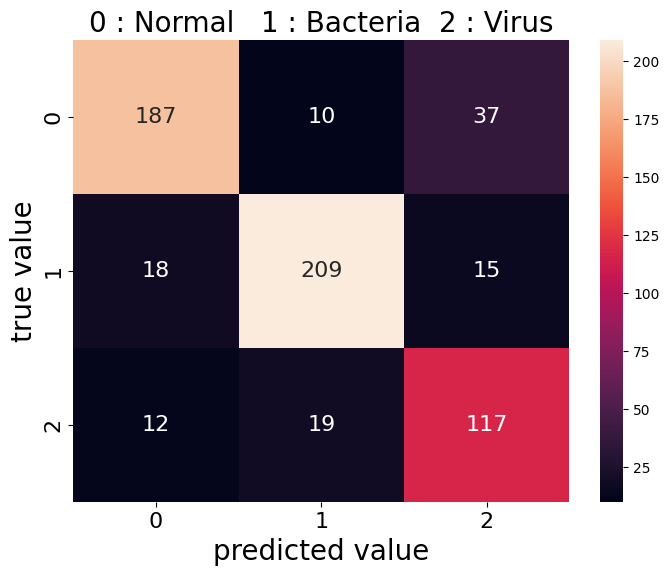

In [ ]:
mat = confusion_matrix(y_test, y_pred)
print(mat)

plt.figure(figsize=(8,6))
sns.heatmap(mat, square=False, annot=True, fmt ='d', cbar=True, annot_kws={"size": 16})
plt.title('0 : Normal   1 : Bacteria  2 : Virus', fontsize = 20)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
plt.xlabel('predicted value', fontsize = 20)
plt.ylabel('true value', fontsize = 20)
plt.show()

### Calculating *precision*, *recall*, *accuracy*, *F1_score* & *F2_score* for < STAGE 3 >

In [ ]:
# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Overall Accuracy: {:.4f}".format(acc))

# Precision, Recall, F1 score (per class)
precision = precision_score(y_test, y_pred, average=None)  # array of size 3
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)
f2 = fbeta_score(y_test, y_pred, beta=2, average=None)

for i, cls in enumerate(['Normal', 'Bacteria', 'Virus']):
    print("\nClass:", cls)
    print("  Precision: {:.4f}".format(precision[i]))
    print("  Recall:    {:.4f}".format(recall[i]))
    print("  F1-score:  {:.4f}".format(f1[i]))
    print("  F2-score:  {:.4f}".format(f2[i]))

# Macro / Micro averages
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f2_macro = fbeta_score(y_test, y_pred, beta=2, average='macro')

print("\nMacro Average Precision: {:.4f}".format(precision_macro))
print("Macro Average Recall: {:.4f}".format(recall_macro))
print("Macro Average F1-score: {:.4f}".format(f1_macro))
print("Macro Average F2-score: {:.4f}".format(f2_macro))

Overall Accuracy: 0.8221

Class: Normal
  Precision: 0.8618
  Recall:    0.7991
  F1-score:  0.8293
  F2-score:  0.8109

Class: Bacteria
  Precision: 0.8782
  Recall:    0.8636
  F1-score:  0.8708
  F2-score:  0.8665

Class: Virus
  Precision: 0.6923
  Recall:    0.7905
  F1-score:  0.7382
  F2-score:  0.7687

Macro Average Precision: 0.8107
Macro Average Recall: 0.8178
Macro Average F1-score: 0.8128
Macro Average F2-score: 0.8154


<a id="Result"></a>
## Results(B)
> + 由以上結果可知：經過 30 epochs (i.e., Stage 1 + Stage 2) 的訓練，**Recall** 值接近 100%；這代表預測模型的 false-negative 誤判部分 (亦即，將 Pneumonia 誤判成 Normal 的狀況) 將會下降趨近 0。
> + 然而， **F1 score** 仍然還有改進的空間；這是因為 false-positive 誤診部分 (亦即，將 Normal 誤判成 Pneumonia 的狀況) 造成 **Precision** 的精確值偏低的緣故。
> + 請想想看，如何改進模型或調校預測模型參數 (hyperparameters)，進而能夠使其 **F1 score** 數值上升。  Good luck！

以下將 From-Coarse-to-Fine 全程訓練過程的 Learning Curves 繪製如下，做為參考：

In [ ]:
acc_total = history_no_data_aug.history['accuracy'] + history_data_aug.history['accuracy'] + history_unfreeze.history['accuracy']
val_acc_total = history_no_data_aug.history['val_accuracy'] + history_data_aug.history['val_accuracy'] + history_unfreeze.history['val_accuracy']

loss_total = history_no_data_aug.history['loss'] + history_data_aug.history['loss'] + history_unfreeze.history['loss']
val_loss_total = history_no_data_aug.history['val_loss'] + history_data_aug.history['val_loss'] + history_unfreeze.history['val_loss']

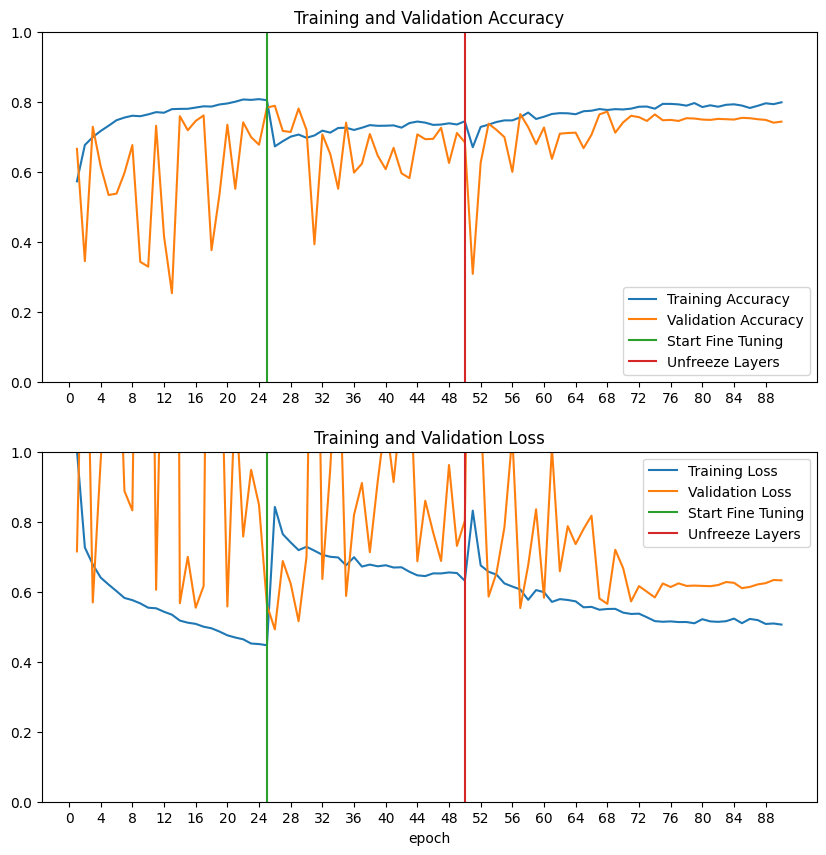

In [ ]:
initial_epochs = epochs_stage_1
second_epochs = epochs_stage_1 + epochs_stage_2
total_epochs = epochs_stage_1 + epochs_stage_2 + epochs_stage_3
epochs_range = range(1, total_epochs + 1)

plt.figure(figsize=(10, 10))
plt.subplot(2, 1, 1)
plt.plot(epochs_range, acc_total, label='Training Accuracy')
plt.plot(epochs_range, val_acc_total, label='Validation Accuracy')
plt.ylim([0, 1])
plt.xticks(range(0,total_epochs+1,4))
plt.plot([initial_epochs,initial_epochs],
          plt.ylim(), label='Start Fine Tuning')
plt.plot([second_epochs,second_epochs],
          plt.ylim(), label='Unfreeze Layers')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(epochs_range, loss_total, label='Training Loss')
plt.plot(epochs_range, val_loss_total, label='Validation Loss')
plt.ylim([0, 1])
plt.xticks(range(0,total_epochs+1,4))
plt.plot([initial_epochs,initial_epochs],
         plt.ylim(), label='Start Fine Tuning')
plt.plot([second_epochs,second_epochs],
          plt.ylim(), label='Unfreeze Layers')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

<a id="SavingEntireModel"></a>
## Saving the Entire Model

In [ ]:
model.save("ResNet50_model.keras")

In [ ]:
# Reload the Keras model (.keras format)
ResNet50_model = tf.keras.models.load_model('ResNet50_model.keras')

# Show the model architecture
ResNet50_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 7, 7, 256) │  4,718,848 │ resnet50[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 256) │      1,024 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 128) │    295,040 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 128) │        512 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 7, 7, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 3, 3, 128) │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        387 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 68,589,706 (261.65 MB)

 Trainable params: 19,993,091 (76.27 MB)

 Non-trainable params: 8,610,432 (32.85 MB)

 Optimizer params: 39,986,183 (152.54 MB)

In [ ]:
# Evaluate the restored model
loss, acc = ResNet50_model.evaluate(x_test, y_test, verbose=1)
print('Test loss:', loss)
print('Test accuracy:', acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 164ms/step - accuracy: 0.8060 - loss: 0.5845
Test loss: 0.5223252177238464
Test accuracy: 0.8221153616905212


In [ ]:
# submission = pd.concat([pd.Series(range(1,(len(pred)+1)),name = "ImageId"),preds],axis = 1)
data_subm = {'ImageId': pd.Series(range(1,(len(y_pred)+1))), 'Prediction': y_pred}
submission = pd.DataFrame(data_subm)
submission = submission.applymap(str)

submission.to_csv("submission.csv",index=False)

/tmp/ipython-input-2856244980.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  submission = submission.applymap(str)


# **Conclusion**

我們使用了MobileNetv2和ResNet50兩個不同的預訓練模型，為了增加準確度，加了數層CNN和Dense層。其後依序做特徵擷取、資料擴增、模型解凍三種方法。\
在fine-tuning過後，準確率達到:\
MobileNetv2 -- accuracy: 0.8227, test accuracy:0.8221 \
ResNet50 -- accuracy: 0.8020, test accuracy:0.8261 \
test準確率從68%~73%-->82%，可以發現在特徵擷取時發生的overfitting已經改善。

但是我的準確率很難再往上增加，無法到九成以上的準確率。
根據分類資料的結果，原因是MobileNetv2和Resnet50都有較多狀況是把'Normal'的圖像判別成'Virus'的類別,也有不少狀況是把'Virus'看成'Bacteria''的類別。



